# 10 - Adaptive modulation and coding (Task 1d)
**Objective.** Use the simulated BLER/BER/text-quality tables to build an AMC rule: *choose the highest-rate MCS whose sentence BLER is $\le10\,\%$*.

## Mechanism
1. **SNR input/estimation** - the receiver reports $E_s/N_0$ (here: the true value, or an estimate from known pilots, see section 4).
2. **Look-up** - read the row of the LUT at the largest grid SNR $\le$ the reported SNR (conservative: BLER decreases with SNR, so a lower grid point can only over-estimate BLER).
3. **Threshold check** - keep MCSs with BLER $\le 0.10$.
4. **Selection** - among them take the highest nominal spectral efficiency $\eta=m\cdot R$ [info bit/channel use]: 1, 1.5, 2, 3, 4, 4.5 for MCS 1-6.
5. **Fallback** - if none qualifies, use the most robust MCS (MCS1, QPSK 1/2) and flag *outage*.
6. **Throughput** - reported both as $\eta$ and as goodput $\eta(1-\text{BLER})$.

**No value is typed in by hand:** the LUT is the Monte-Carlo sweep of notebook 08.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # project root = import root
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
print("project root:", ROOT)

project root: /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1


In [2]:
from task1_conventional import experiments as ex, plotting
MODE = ex.best_available_mode(ROOT)      # "full" once `python main.py --experiment all --mode full` has finished
# MODE = "quick"                         # <- uncomment to force the small debugging data set
print("Using", MODE.upper(), "results", "" if MODE == "full" else "(QUICK MODE: small sample, NOT final results)")
sweep = pd.read_csv(TAB / f"{MODE}_mcs_sweep.csv")
cfg = ex.CONFIG[MODE]
print(f"{len(sweep)} (channel, MCS, SNR) points; {cfg['n_sentences']} sentences x {cfg['reps_awgn']} (AWGN) / {cfg['reps_rayleigh']} (Rayleigh) repetitions per point")

Using FULL results 
528 (channel, MCS, SNR) points; 2000 sentences x 3 (AWGN) / 5 (Rayleigh) repetitions per point


In [3]:
from task1_conventional.amc import AMC, build_lut, amc_with_estimation, estimate_snr_db
from task1_conventional.communication_system import MCS_TABLE
out = ex.run_amc(MODE, ROOT)                          # (re)builds LUT CSVs from the sweep
luts = {c: out[c][0] for c in ("awgn", "rayleigh")}; curves = {c: out[c][1] for c in ("awgn", "rayleigh")}

## 1. Look-up tables (SNR, MCS, BER, BLER, text similarity)

In [4]:
print("LUT columns:", list(luts["awgn"].columns))
display(luts["awgn"].query("snr_db in [8, 10, 12, 14, 16, 18]").round(4).head(18))
for c in luts: print(f"saved results/tables/{MODE}_amc_lut_{c}.csv  ({len(luts[c])} rows)")

LUT columns: ['snr_db', 'mcs', 'modulation', 'rate', 'efficiency', 'ber', 'bler', 'bleu', 'word_acc', 'cos_sim']


,snr_db,mcs,modulation,rate,efficiency,ber,bler,bleu,word_acc,cos_sim
120,8.0,1,QPSK,1/2,1.0,0.0000,0.0000,1.0000,1.0000,1.0000
121,8.0,2,QPSK,3/4,1.5,0.0000,0.0000,1.0000,1.0000,1.0000
122,8.0,3,16QAM,1/2,2.0,0.0004,0.0203,0.9944,0.9968,0.9995
123,8.0,4,16QAM,3/4,3.0,0.2952,0.9792,0.1810,0.2733,0.7617
124,8.0,5,64QAM,2/3,4.0,0.4679,1.0000,0.0256,0.0194,0.5308
125,8.0,6,64QAM,3/4,4.5,0.4803,1.0000,0.0220,0.0079,0.5146
144,10.0,1,QPSK,1/2,1.0,0.0000,0.0000,1.0000,1.0000,1.0000
145,10.0,2,QPSK,3/4,1.5,0.0000,0.0000,1.0000,1.0000,1.0000
146,10.0,3,16QAM,1/2,2.0,0.0000,0.0000,1.0000,1.0000,1.0000
147,10.0,4,16QAM,3/4,3.0,0.0317,0.3883,0.8414,0.8905,0.9814


saved results/tables/full_amc_lut_awgn.csv  (390 rows)
saved results/tables/full_amc_lut_rayleigh.csv  (138 rows)


## 2. Selection in action

In [5]:
amc = AMC(luts["awgn"], 0.10)
for snr in (-5, 0, 3.2, 6, 9.5, 13, 17.4, 25):
    r = amc.select(snr); print(f"SNR {snr:6.1f} dB -> MCS{r['mcs']}  eta={r['efficiency']:.1f}  BLER(table)={r['bler']}  outage={r['outage']}")

SNR   -5.0 dB -> MCS1  eta=1.0  BLER(table)=nan  outage=True
SNR    0.0 dB -> MCS1  eta=1.0  BLER(table)=0.9543333333333334  outage=True
SNR    3.2 dB -> MCS1  eta=1.0  BLER(table)=0.02  outage=False
SNR    6.0 dB -> MCS2  eta=1.5  BLER(table)=0.0056666666666666  outage=False
SNR    9.5 dB -> MCS3  eta=2.0  BLER(table)=0.0003333333333333  outage=False
SNR   13.0 dB -> MCS4  eta=3.0  BLER(table)=0.0001666666666666  outage=False
SNR   17.4 dB -> MCS6  eta=4.5  BLER(table)=0.012  outage=False
SNR   25.0 dB -> MCS6  eta=4.5  BLER(table)=0.0  outage=False


## 3. AMC curves (AWGN and Rayleigh LUTs)

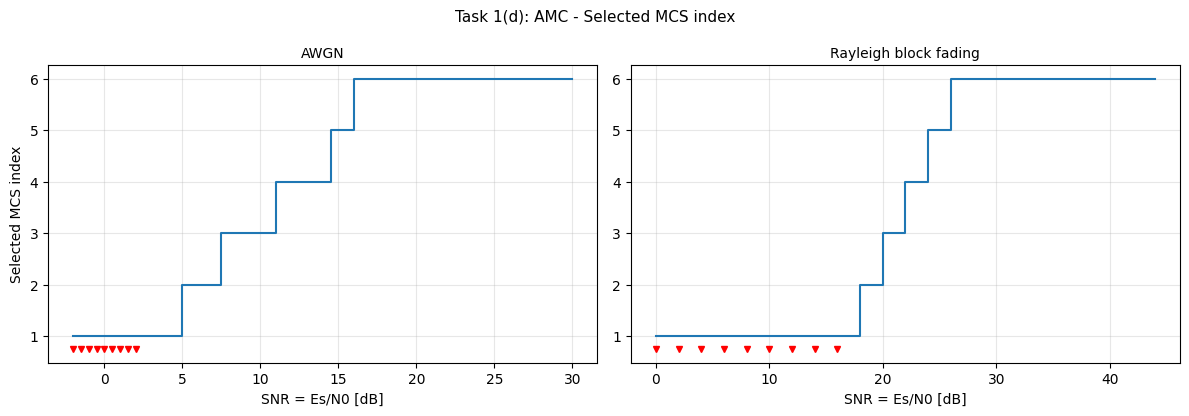

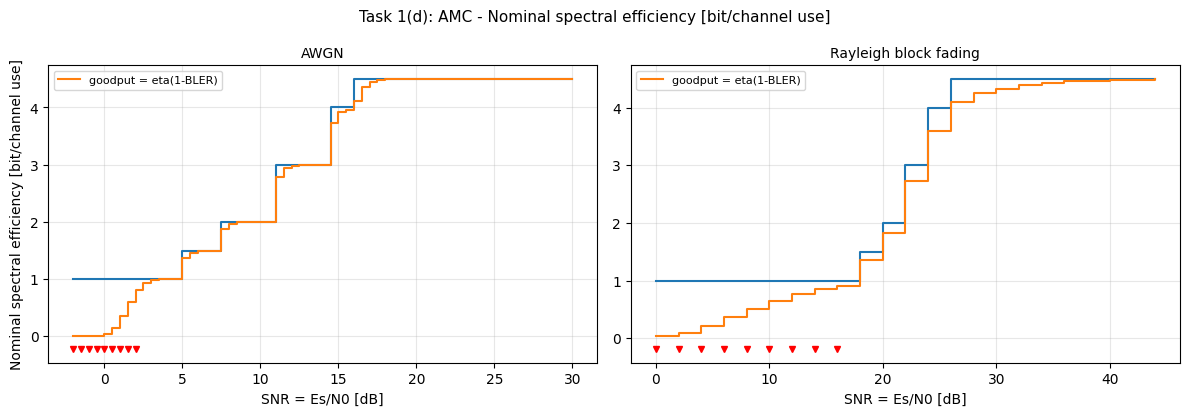

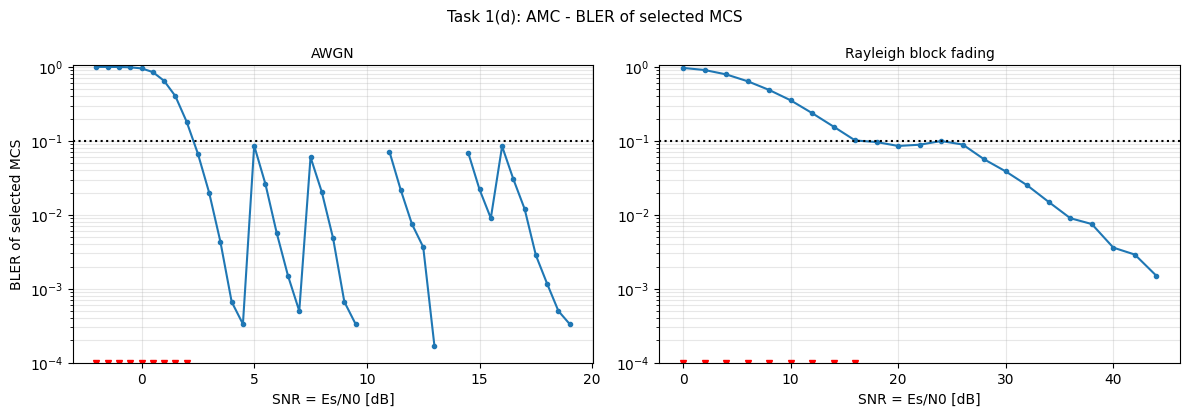

In [6]:
figs = plotting.plot_amc(curves, MODE, str(FIG / MODE)); plt.show()

In [7]:
for chn, cv in curves.items():
    sw = cv[cv.mcs.diff().fillna(0) != 0][["snr_db", "mcs", "efficiency", "bler"]]
    print(f"--- {chn}: switching points (SNR grid where the selected MCS changes)"); display(sw.round(4))
    print("outage SNRs (no MCS meets BLER<=10%):", cv[cv.outage].snr_db.tolist())
    print("max BLER of selected MCS over non-outage SNRs: %.4f  (target 0.10)" % cv[~cv.outage].bler.max())
    assert (cv[~cv.outage].bler <= 0.10 + 1e-12).all()

--- awgn: switching points (SNR grid where the selected MCS changes)


,snr_db,mcs,efficiency,bler
14,5.0,2,1.5,0.0860
19,7.5,3,2.0,0.0602
26,11.0,4,3.0,0.0717
33,14.5,5,4.0,0.0687
36,16.0,6,4.5,0.0845


outage SNRs (no MCS meets BLER<=10%): [-2.0, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 2.0]
max BLER of selected MCS over non-outage SNRs: 0.0860  (target 0.10)
--- rayleigh: switching points (SNR grid where the selected MCS changes)


,snr_db,mcs,efficiency,bler
9,18.0,2,1.5,0.0963
10,20.0,3,2.0,0.0853
11,22.0,4,3.0,0.0887
12,24.0,5,4.0,0.0994
13,26.0,6,4.5,0.0892


outage SNRs (no MCS meets BLER<=10%): [0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0]
max BLER of selected MCS over non-outage SNRs: 0.0994  (target 0.10)


### Which LUT should Task 3 use?
In Task 3 every RB $n$ of user $u$ has its own *instantaneous* SNR $\gamma_{u,n}$ (path loss, shadowing and one Rayleigh fade, constant within the RB). Conditioned on that fade the RB is an **AWGN channel** at $\gamma_{u,n}$, so the **AWGN LUT** is the right table for per-RB link adaptation. The Rayleigh LUT here answers a different question - the BLER averaged over fading at a given *average* SNR (what a long-term link-adaptation loop would see).

## 4. Robustness: selecting with an *estimated* SNR (AWGN)
The estimator averages $|y-x|^2$ over $N_p$ known pilot symbols; its error shrinks like $1/\sqrt{N_p}$. Selection uses the estimate, the outcome is scored with the table at the **true** SNR.

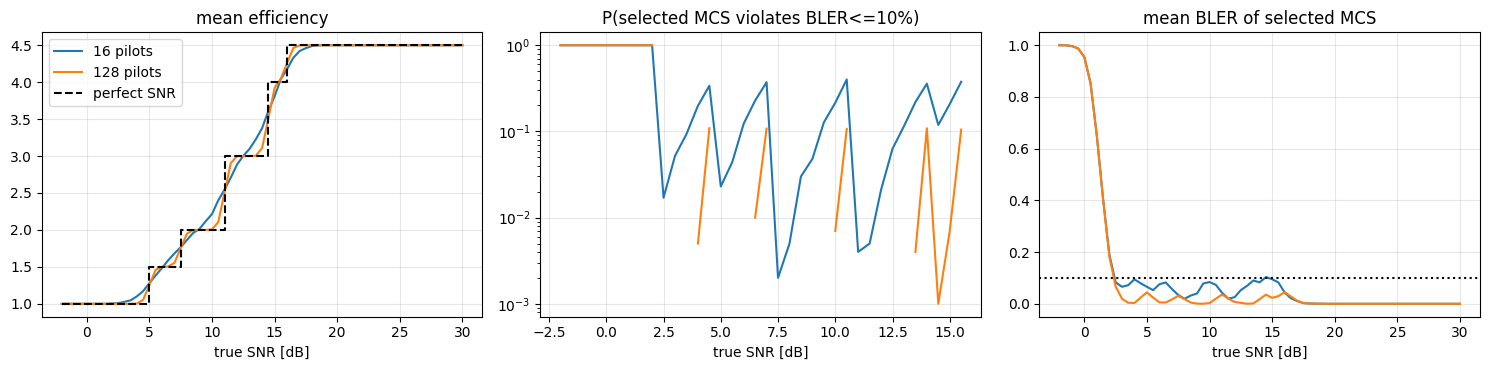

          mean_efficiency  p_bler_violation
n_pilots                                   
16                 3.0508            0.1970
128                3.0367            0.1473


In [8]:
est = out["estimation"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for n, g in est.groupby("n_pilots"):
    ax[0].plot(g.snr_db, g.mean_efficiency, label=f"{n} pilots"); ax[1].semilogy(g.snr_db, g.p_bler_violation.replace(0, np.nan), label=f"{n} pilots"); ax[2].plot(g.snr_db, g.mean_selected_bler, label=f"{n} pilots")
base = curves["awgn"]; ax[0].step(base.snr_db, base.efficiency, "k--", where="post", label="perfect SNR"); ax[0].set_title("mean efficiency"); ax[0].legend()
ax[1].set_title("P(selected MCS violates BLER<=10%)"); ax[2].set_title("mean BLER of selected MCS"); ax[2].axhline(0.1, color="k", ls=":")
for a in ax: a.set_xlabel("true SNR [dB]")
fig.tight_layout(); fig.savefig(FIG / f"{MODE}_amc_snr_estimation.png", dpi=150); plt.show()
print(est.groupby("n_pilots")[["mean_efficiency", "p_bler_violation"]].mean().round(4))

**Reading it.** With few pilots the estimate is noisy; because the BLER cliff is so steep (notebook 09), an SNR error of only 1-2 dB just below a switching point can select an MCS that violates the 10 % target. More pilots (or a back-off margin of ~1-2 dB) trade a little spectral efficiency for a lower violation probability.

## 5. Summary table for the report

In [9]:
thr = []
for chn, cv in curves.items():
    for m in MCS_TABLE:
        s = cv[(cv.mcs == m.index) & (~cv.outage)]
        thr.append(dict(channel=chn, MCS=m.name, efficiency=m.efficiency, first_SNR_selected_dB=s.snr_db.min() if len(s) else np.nan))
thr = pd.DataFrame(thr); display(thr.pivot(index="MCS", columns="channel", values="first_SNR_selected_dB")); thr.to_csv(TAB / f"{MODE}_amc_switching_snr.csv", index=False)

channel,awgn,rayleigh
MCS,,
MCS1: QPSK 1/2,2.5,NaN
MCS2: QPSK 3/4,5.0,18.0
MCS3: 16QAM 1/2,7.5,20.0
MCS4: 16QAM 3/4,11.0,22.0
MCS5: 64QAM 2/3,14.5,24.0
MCS6: 64QAM 3/4,16.0,26.0
